In [1]:
import sys
sys.path.append('../scripts')
from utils.cftp_func import *
import glob
from scipy.stats import linregress

In [2]:
julia_colors = [
    '#00A9AD',  # teal
    '#E28F41',  # orange
    '#389826',  # green
    '#9558B2',  # purple
    '#CB3C33',  # red
    '#7C7C7C',  # grey
    '#BB7DC0',  # light purple
    '#4063D8',  # blue
]
from cycler import cycler
plt.rcParams['axes.prop_cycle'] = cycler(color=julia_colors)
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False
plt.rcParams['legend.frameon'] = False

plt.rcParams['font.size'] = 14          
plt.rcParams['axes.labelsize'] = 16     
plt.rcParams['xtick.labelsize'] = 13
plt.rcParams['ytick.labelsize'] = 13
plt.rcParams['legend.fontsize'] = 12
plt.rcParams['axes.titlesize'] = 16

In [3]:
graph_type = 'EA3D'
coup_type = 'ising'
d = 3
if graph_type == 'ER' and coup_type == 'ising':
    beta_SG = np.arctanh(np.sqrt(1/d))
    beta_uni = np.arctanh(1/d)
    print(f"beta_uni = {beta_uni:.6f}, beta_SG = {beta_SG:.6f}")
elif graph_type == 'ER' and coup_type == 'gauss':
    beta_uni = solve_beta_critical_gauss(d=d)
    print(f"beta_uni = {beta_uni:.6f}")
elif graph_type == 'RR' and coup_type == 'ising':
    beta_SG = np.arctanh(np.sqrt(1/(d-1)))
    beta_uni = np.arctanh(1/(d-1))
    beta_dob = np.arctanh(1/d)
    print(f"beta_dob = {beta_dob:.6f}, beta_uni = {beta_uni:.6f}, beta_SG = {beta_SG:.6f}")
elif graph_type == 'EA2D' and coup_type == 'ising':
    beta_uni = np.arctanh(1/3)
    beta_DS = 0.58
    print(f"beta_uni = {beta_uni:.6f}, beta_DS = {beta_DS}")
elif graph_type == 'EA3D' and coup_type == 'ising':
    beta_uni = np.arctanh(1/5)
    beta_DS = 0.33
    print(f"beta_uni = {beta_uni:.6f}, beta_DS = {beta_DS}")


beta_uni = 0.202733, beta_DS = 0.33


In [4]:
folder_data = f"perm/{graph_type}_{coup_type}/coal_time_DS_{graph_type}_{coup_type}" #"tmp"

dfs = [pd.read_csv(f) for f in glob.glob(f'../results/{folder_data}/coal_time_DS_{graph_type}_{coup_type}_d{d}_beta*.csv')]
df = pd.concat(dfs, ignore_index=True)

if graph_type in ('EA2D', 'F2D'):
    print("betas:", sorted(df['beta'].unique()), "\nL:", sorted(df['N'].unique()), "\nsizes:", sorted(df['N'].unique()**2))
elif graph_type in ('EA3D', 'F3D'):
    print("betas:", sorted(df['beta'].unique()), "\nL:", sorted(df['N'].unique()), "\nsizes:", sorted(df['N'].unique()**3))
else:
    print("betas:", sorted(df['beta'].unique()), "\nsizes:", sorted(df['N'].unique()))
df

betas: [0.19, 0.2, 0.205, 0.21, 0.24, 0.25, 0.255, 0.26, 0.27] 
L: [6, 8, 10, 12, 13, 15, 18, 20, 23, 30, 40, 60, 100] 
sizes: [216, 512, 1000, 1728, 2197, 3375, 5832, 8000, 12167, 27000, 64000, 216000, 1000000]


,beta,sampler,lazy,n_configs,n_runs,max_iter,N,n_coal,mean_coal_time,std_coal_time
0,0.24,F_beta_Glauber,False,2,100,1000000000,6,100,9.202010e+03,6.830438e+03
1,0.24,F_beta_Glauber,False,2,100,1000000000,8,100,3.367177e+04,1.653274e+04
2,0.24,F_beta_Glauber,False,2,100,1000000000,10,100,7.792657e+04,3.388946e+04
3,0.24,F_beta_Glauber,False,2,100,1000000000,12,100,1.876915e+05,9.202942e+04
4,0.24,F_beta_Glauber,False,2,100,1000000000,15,100,4.680589e+05,2.040394e+05
...,...,...,...,...,...,...,...,...,...,...
66,0.25,F_beta_Glauber,False,2,100,1000000000,20,100,2.795061e+06,1.424558e+06
67,0.25,F_beta_Glauber,False,2,100,1000000000,12,100,3.290748e+05,1.860990e+05
68,0.25,F_beta_Glauber,False,2,100,1000000000,30,100,1.564716e+07,5.916685e+06
69,0.25,F_beta_Glauber,False,2,100,1000000000,40,100,4.675168e+07,1.545799e+07


# Scaling of coalescence times

In [5]:
max_iter_plot = [10**9, 10**10]
if graph_type == 'ER' and coup_type == 'ising':
    beta_plot = [0.24,0.25,0.26,0.27] # beta selection for plotting
elif graph_type == 'ER' and coup_type == 'gauss':
    beta_plot = [0.32, 0.33, 0.34,0.35, 0.36] # beta selection for plotting
elif graph_type == 'EA2D' and coup_type == 'ising':
    beta_plot = [0.5,0.56,0.57,0.59,0.61] #df['beta'].unique()
else:
    beta_plot = df['beta'].unique()

mask = (
    (df['n_coal'] >= df['n_runs']-1) & # plot only beta values for which every run has coalesced (for unbiased averages)
    (df['max_iter'].isin(max_iter_plot)) &
    (df['beta'].isin(beta_plot)) 
)
df_filtered = df[mask]

best_runs = df_filtered.groupby('beta')['n_runs'].transform('max')
df_filtered = df_filtered[df_filtered['n_runs'] == best_runs]

df_filtered = (df_filtered.sort_values('max_iter', ascending=False)
               .drop_duplicates(subset=['beta', 'N'], keep='first')
               .sort_values(['beta', 'N']))

#df_filtered

0.24 100 1000000000 [  6   8  10  12  15  20  30  40  60 100]
0.25 100 1000000000 [ 6  8 10 12 15 20 30 40 60]
0.26 100 1000000000 [ 6  8 10 12 15 18]
0.27 100 1000000000 [ 6  8 10 12]


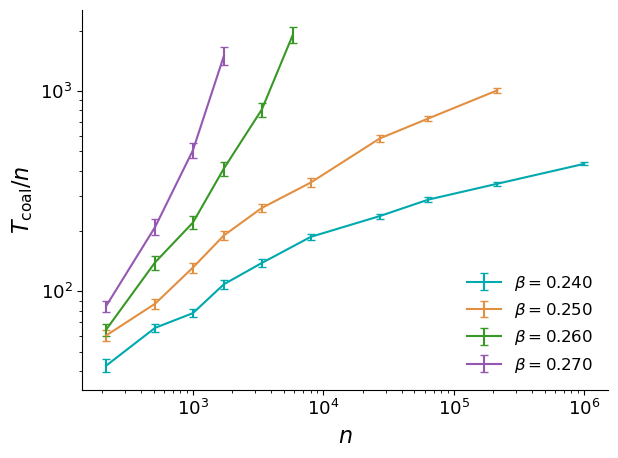

In [10]:
fig, ax = plt.subplots()

for beta in sorted(df_filtered['beta'].unique()):
    if coup_type == 'gauss' and (beta < 0.31):# or beta >= 0.35):
        continue
    if graph_type == 'SK' and beta < 0.05:
        continue
    if graph_type == 'EA3D' and (beta <= 0.23 or beta == 0.255):
        continue
    sub_df = df_filtered[df_filtered['beta'] == beta].sort_values('N')
    N = sub_df['N'].values
    T = sub_df['mean_coal_time'].values
    n_runs_plot = sub_df['n_runs'].values       
    print(beta, n_runs_plot[0], max_iter_plot[0], N)   
    sT = sub_df['std_coal_time'].values/np.sqrt(n_runs_plot)
    if graph_type in ('EA2D', 'F2D'):
        N = N**2
    if graph_type in ('EA3D', 'F3D'):
        N = N**3
    ax.errorbar(N, T/N,
                yerr=sT/N,
                label=rf'$\beta={beta:.3f}$',
                capsize=3)

ax.set_xlabel(rf'$n$')
ax.set_ylabel(rf'$T_\mathrm{{coal}} / n$')
ax.set_xscale('log')
ax.set_yscale('log')
ax.legend(loc='lower right')
plt.tight_layout()
plt.show()

In [11]:
fig.savefig(f'../results/{folder_data}/coal_DS_loglog_{graph_type}_{coup_type}_d{d}.pdf', bbox_inches='tight')